 identidad_%  llamados_ARG  recall  precision    f1  accuracy
          20           785   0.760      0.968 0.852     0.868
          30           736   0.720      0.978 0.829     0.852
          40           525   0.516      0.983 0.677     0.754
          50           353   0.351      0.994 0.519     0.674
          60           292   0.292      1.000 0.452     0.646
          70           246   0.246      1.000 0.395     0.623


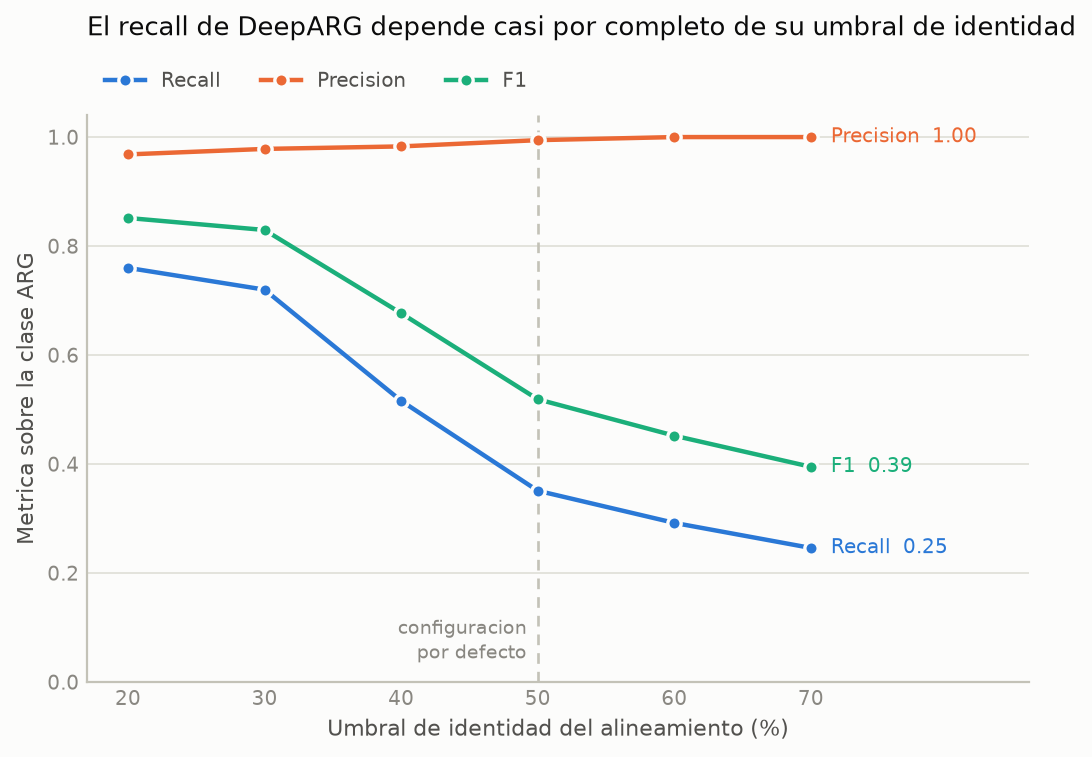

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

BASE     = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias"
LABELS   = f"{BASE}/data/interim/muestra_genes_labels.tsv"
UMBRALES = [20, 30, 40, 50, 60, 70]

# ---------- verdad de referencia ----------
truth = pd.read_csv(LABELS, sep="\t")
gid_col, lab_col = truth.columns[0], truth.columns[1]
truth = truth[[gid_col, lab_col]].rename(columns={gid_col: "gid", lab_col: "y_true"})
truth["y_true"] = truth["y_true"].astype(int)
truth["key"] = truth["gid"].str.split().str[0]

# ---------- barrido de umbrales ----------
filas = []
for idv in UMBRALES:
    det = pd.read_csv(f"{BASE}/results/deeparg_id{idv}.mapping.ARG", sep="\t")
    ids = set(det[det.columns[3]].astype(str).unique())   # entrada nucleotido: NO hay sufijo de Prodigal
    y_pred = truth["key"].isin(ids).astype(int)
    p, r, f, _ = precision_recall_fscore_support(truth["y_true"], y_pred, labels=[1], average=None)
    filas.append({"identidad_%": idv, "llamados_ARG": int(y_pred.sum()),
                  "recall": r[0], "precision": p[0], "f1": f[0],
                  "accuracy": accuracy_score(truth["y_true"], y_pred)})

tabla = pd.DataFrame(filas)
print(tabla.round(3).to_string(index=False))
tabla.to_csv(f"{BASE}/results/curva_deeparg_identidad.csv", index=False)

# ---------- figura ----------
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLS = {"recall": "#2a78d6", "precision": "#eb6834", "f1": "#1baf7a"}
ETIQ = {"recall": "Recall", "precision": "Precision", "f1": "F1"}

fig, ax = plt.subplots(figsize=(7.6, 4.6), dpi=160)
fig.patch.set_facecolor(SURF); ax.set_facecolor(SURF)

# linea de referencia: configuracion por defecto de la herramienta
ax.axvline(50, color=AXIS, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(49.2, 0.03, "configuracion\npor defecto", color=MUTED, fontsize=8.5,
        ha="right", va="bottom", linespacing=1.3)

for m in ["recall", "precision", "f1"]:
    ax.plot(tabla["identidad_%"], tabla[m], color=COLS[m], lw=2,
            marker="o", ms=6, mec=SURF, mew=1.5, zorder=3, label=ETIQ[m])
    ax.annotate(f"{ETIQ[m]}  {tabla[m].iloc[-1]:.2f}",
                (tabla["identidad_%"].iloc[-1], tabla[m].iloc[-1]),
                textcoords="offset points", xytext=(9, 0),
                ha="left", va="center", color=COLS[m], fontsize=9)

ax.set_xlim(17, 86); ax.set_ylim(0, 1.04)
ax.set_xticks(UMBRALES)
ax.set_xlabel("Umbral de identidad del alineamiento (%)", color=INK2, fontsize=10)
ax.set_ylabel("Metrica sobre la clase ARG", color=INK2, fontsize=10)
ax.set_title("El recall de DeepARG depende casi por completo de su umbral de identidad",
             color=INK, fontsize=11.5, loc="left", pad=36)

ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color(AXIS); ax.spines[s].set_linewidth(1)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
          frameon=False, fontsize=9, labelcolor=INK2)

plt.savefig(f"{BASE}/results/fig_deeparg_identidad.png",  dpi=300, facecolor=SURF, bbox_inches="tight")
plt.savefig(f"{BASE}/results/fig_deeparg_identidad.tiff", dpi=300, facecolor=SURF, bbox_inches="tight")
plt.show()